# Rainfall and Agricultural Productivity Analysis
**Student Name:** Shiva Kumar  
**Roll Number:** 160125737125

## Objective
Analyze how annual rainfall relates to crop productivity, while also examining temperature, fertilizer use, and irrigation coverage.

**Dataset note:** This is a small illustrative dataset created for educational analysis. It is not official or measured regional data.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Import libraries

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# If the CSV is in the same folder as this notebook, this will work.
csv_file = Path('Rainfall_Agricultural_Productivity_Shiva_Kumar.csv')
df = pd.read_csv(csv_file)
df.head()

,Year,Region,Annual_Rainfall_mm,Average_Temperature_C,Fertilizer_kg_per_ha,Irrigation_Coverage_Percent,Crop_Productivity_tonnes_per_ha
0,2015,Region A,720,27.1,85,35,2.1
1,2016,Region A,810,26.8,90,37,2.4
2,2017,Region A,765,27.3,88,38,2.3
3,2018,Region A,690,27.6,82,36,1.9
4,2019,Region A,940,26.4,95,42,2.8


## 2. Inspect and summarize the dataset

In [12]:
print('Dataset shape:', df.shape)
print('\nColumn data types:')
print(df.dtypes)
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nSummary statistics:')
print(df.select_dtypes(include='number').describe().round(2))

Dataset shape: (10, 7)

Column data types:
Year                                 int64
Region                              object
Annual_Rainfall_mm                   int64
Average_Temperature_C              float64
Fertilizer_kg_per_ha                 int64
Irrigation_Coverage_Percent          int64
Crop_Productivity_tonnes_per_ha    float64
dtype: object

Missing values per column:
Year                               0
Region                             0
Annual_Rainfall_mm                 0
Average_Temperature_C              0
Fertilizer_kg_per_ha               0
Irrigation_Coverage_Percent        0
Crop_Productivity_tonnes_per_ha    0
dtype: int64

Summary statistics:
          Year  Annual_Rainfall_mm  Average_Temperature_C  \
count    10.00               10.00                  10.00   
mean   2019.50              838.00                  26.85   
std       3.03              102.42                   0.42   
min    2015.00              690.00                  26.20   
25%    2017.25  

## 3. Visualize rainfall and productivity over time

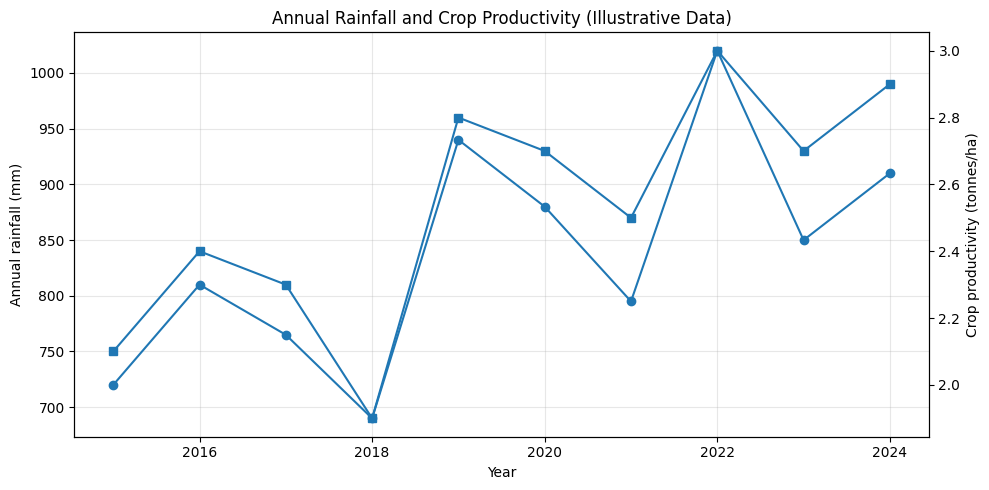

In [13]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df['Year'], df['Annual_Rainfall_mm'], marker='o', label='Annual rainfall (mm)')
ax1.set_xlabel('Year')
ax1.set_ylabel('Annual rainfall (mm)')
ax1.grid(True, alpha=0.3)
ax2 = ax1.twinx()
ax2.plot(df['Year'], df['Crop_Productivity_tonnes_per_ha'], marker='s', label='Crop productivity (tonnes/ha)')
ax2.set_ylabel('Crop productivity (tonnes/ha)')
plt.title('Annual Rainfall and Crop Productivity (Illustrative Data)')
fig.tight_layout()
plt.show()

## 4. Check the relationship between rainfall and productivity

Pearson correlation: 0.959


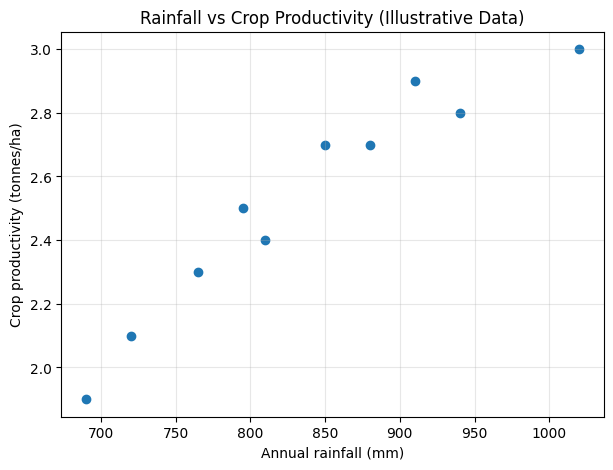

Note: Correlation describes association, not proof that rainfall alone causes productivity changes.


In [14]:
correlation = df['Annual_Rainfall_mm'].corr(df['Crop_Productivity_tonnes_per_ha'])
print(f'Pearson correlation: {correlation:.3f}')

plt.figure(figsize=(7, 5))
plt.scatter(df['Annual_Rainfall_mm'], df['Crop_Productivity_tonnes_per_ha'])
plt.xlabel('Annual rainfall (mm)')
plt.ylabel('Crop productivity (tonnes/ha)')
plt.title('Rainfall vs Crop Productivity (Illustrative Data)')
plt.grid(True, alpha=0.3)
plt.show()

print('Note: Correlation describes association, not proof that rainfall alone causes productivity changes.')

## 5. Compare additional agricultural factors

In [15]:
factors = ['Annual_Rainfall_mm', 'Average_Temperature_C', 'Fertilizer_kg_per_ha',
           'Irrigation_Coverage_Percent', 'Crop_Productivity_tonnes_per_ha']
df[factors].corr().round(2)

,Annual_Rainfall_mm,Average_Temperature_C,Fertilizer_kg_per_ha,Irrigation_Coverage_Percent,Crop_Productivity_tonnes_per_ha
Annual_Rainfall_mm,1.00,-0.95,0.93,0.78,0.96
Average_Temperature_C,-0.95,1.00,-0.88,-0.70,-0.92
Fertilizer_kg_per_ha,0.93,-0.88,1.00,0.93,0.98
Irrigation_Coverage_Percent,0.78,-0.70,0.93,1.00,0.89
Crop_Productivity_tonnes_per_ha,0.96,-0.92,0.98,0.89,1.00


## 6. Simple findings and conclusion

In [16]:
best_year = df.loc[df['Crop_Productivity_tonnes_per_ha'].idxmax()]
lowest_year = df.loc[df['Crop_Productivity_tonnes_per_ha'].idxmin()]
print(f"Highest productivity: {best_year['Year']:.0f} ({best_year['Crop_Productivity_tonnes_per_ha']:.1f} tonnes/ha)")
print(f"Lowest productivity: {lowest_year['Year']:.0f} ({lowest_year['Crop_Productivity_tonnes_per_ha']:.1f} tonnes/ha)")
print('\nConclusion: Rainfall is an important factor in agriculture, but crop productivity also depends on temperature, irrigation, soil, crop type, and fertilizer. Use verified local data before drawing real-world conclusions.')

Highest productivity: 2022 (3.0 tonnes/ha)
Lowest productivity: 2018 (1.9 tonnes/ha)

Conclusion: Rainfall is an important factor in agriculture, but crop productivity also depends on temperature, irrigation, soil, crop type, and fertilizer. Use verified local data before drawing real-world conclusions.


## How to run
1. Keep this `.ipynb` notebook and the CSV file in the same folder.
2. Open the notebook in Jupyter Notebook, JupyterLab, or Google Colab.
3. Run the cells from top to bottom.
4. If using Google Colab, upload the CSV file before running the import cell.